
WTG170 — SCADA / LiDAR / MET MAST

LiDAR source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\06_research_synthesis\02_lidar_all_10min.csv

Mast-wake source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z\11_all_aligned_observations.csv

DATA COVERAGE


,stage,records
0,WTG170 SCADA records,39018
1,SCADA valid,37515
2,LiDAR complete and plausible,14946
3,Mast 3–25 m/s,36378
4,All three valid,14851
5,All three + WTG170 low predicted wake,12671
6,All three + target AND mast low wake,12565
7,Joint low wake + mast 7–10 m/s,3051



THREE-SOURCE MEASUREMENT DIFFERENCES
Means, medians and 95% day-bootstrap intervals


,sample,records,days,scada_minus_mast_mean_ms,scada_minus_mast_median_ms,scada_minus_mast_mean_absolute_ms,scada_minus_mast_ci_low,scada_minus_mast_ci_high,lidar_minus_mast_mean_ms,lidar_minus_mast_median_ms,lidar_minus_mast_mean_absolute_ms,lidar_minus_mast_ci_low,lidar_minus_mast_ci_high,scada_minus_lidar_mean_ms,scada_minus_lidar_median_ms,scada_minus_lidar_mean_absolute_ms,scada_minus_lidar_ci_low,scada_minus_lidar_ci_high
0,All three valid,14851,132,-1.633,-1.593,2.177,-1.759,-1.501,-2.169,-2.056,2.428,-2.300,-2.039,0.536,0.471,0.617,0.478,0.600
1,All three + WTG170 low predicted wake,12671,131,-1.688,-1.621,2.257,-1.825,-1.540,-2.276,-2.182,2.537,-2.404,-2.130,0.588,0.518,0.664,0.522,0.663
2,All three + target AND mast low wake,12565,131,-1.696,-1.639,2.268,-1.836,-1.547,-2.289,-2.205,2.550,-2.420,-2.143,0.593,0.520,0.668,0.525,0.668
3,Joint low wake + mast 7–10 m/s,3051,125,-0.663,-0.650,1.473,-0.858,-0.467,-1.211,-1.246,1.599,-1.389,-1.038,0.548,0.536,0.567,0.511,0.590



MONTHLY DIFFERENCES


,month,records,days,scada_minus_mast_mean_ms,lidar_minus_mast_mean_ms,scada_minus_lidar_mean_ms
0,2026-05,2497,30,-1.847,-2.511,0.664
1,2026-06,3105,29,-1.604,-2.151,0.546
2,2026-07,2505,25,-1.382,-2.095,0.714
3,2026-08,3160,31,-1.810,-2.330,0.520
4,2026-09,1404,16,-1.859,-2.336,0.477



TOP DATES BY SCADA–LiDAR DISAGREEMENT


C:\Users\alex-\AppData\Local\Temp\ipykernel_113500\4257632404.py:722: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily.head(10).round(3))


,day,records,mean_abs_scada_lidar_ms,mean_scada_minus_mast_ms,mean_lidar_minus_mast_ms
130,2026-09-17 00:00:00+00:00,9,5.929,-0.090,-6.019
129,2026-09-16 00:00:00+00:00,5,5.637,0.394,-5.244
57,2026-06-29 00:00:00+00:00,56,3.872,-1.556,-5.243
80,2026-07-28 00:00:00+00:00,131,2.133,-0.292,-2.425
15,2026-05-17 00:00:00+00:00,83,1.853,-1.571,-3.377
4,2026-05-06 00:00:00+00:00,103,1.811,-1.118,-2.929
14,2026-05-16 00:00:00+00:00,104,1.719,-2.862,-4.562
56,2026-06-28 00:00:00+00:00,79,1.607,0.348,-0.705
71,2026-07-13 00:00:00+00:00,26,1.605,0.275,-1.330
81,2026-07-29 00:00:00+00:00,125,1.570,0.419,-1.151


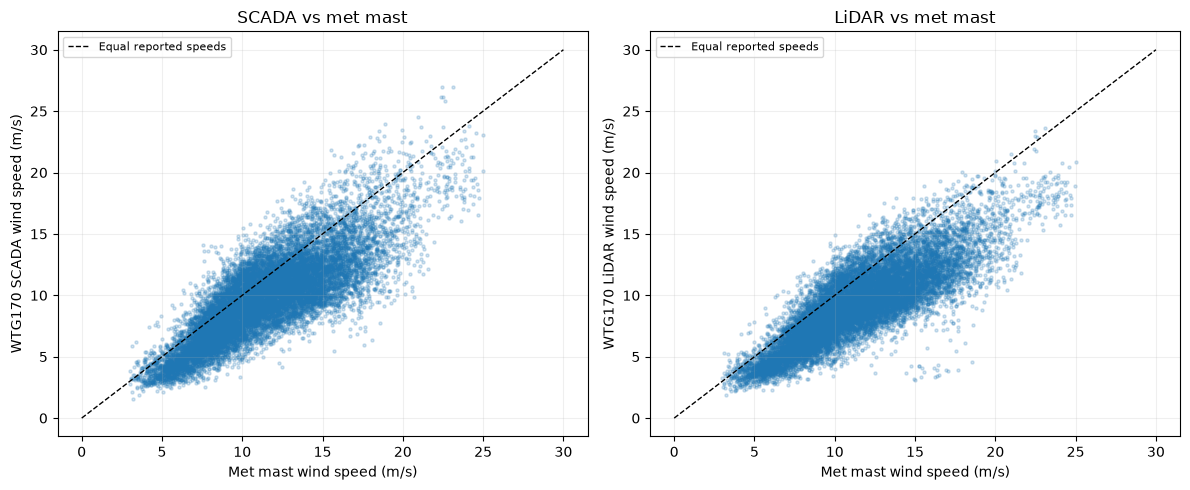

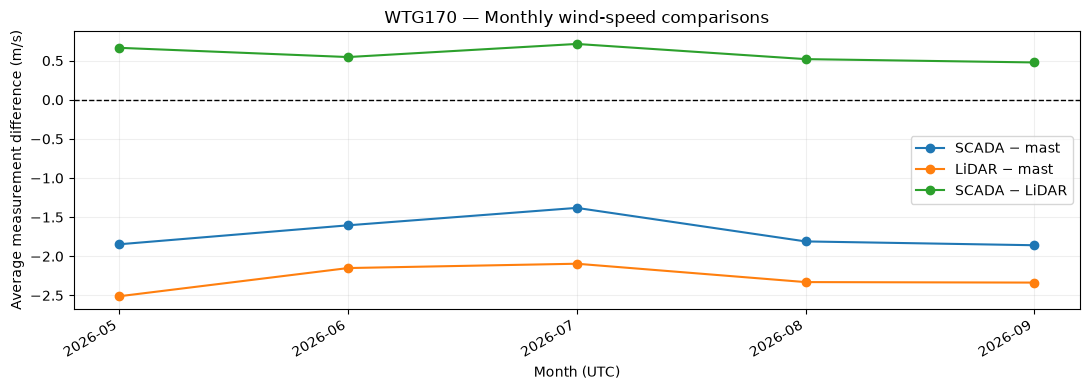

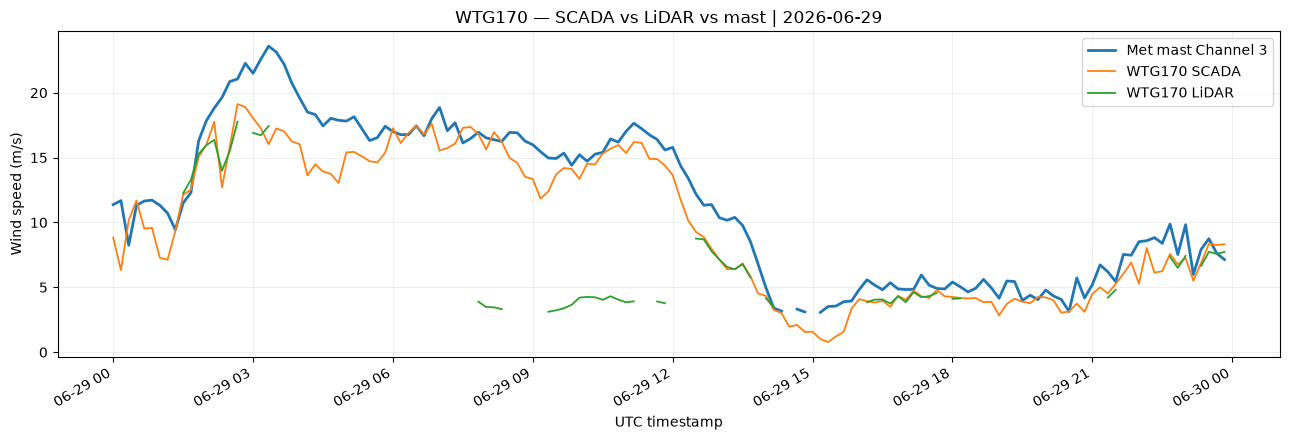

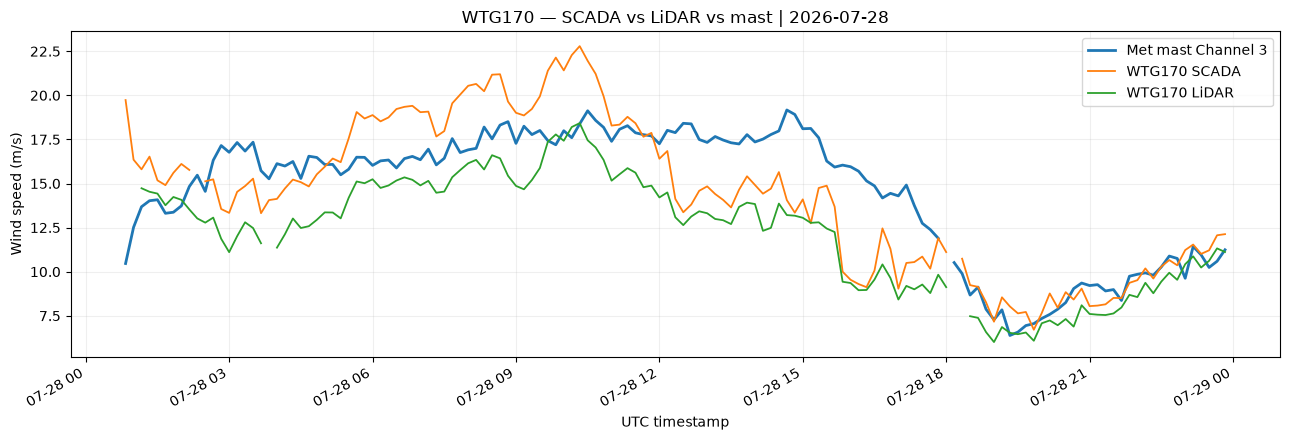

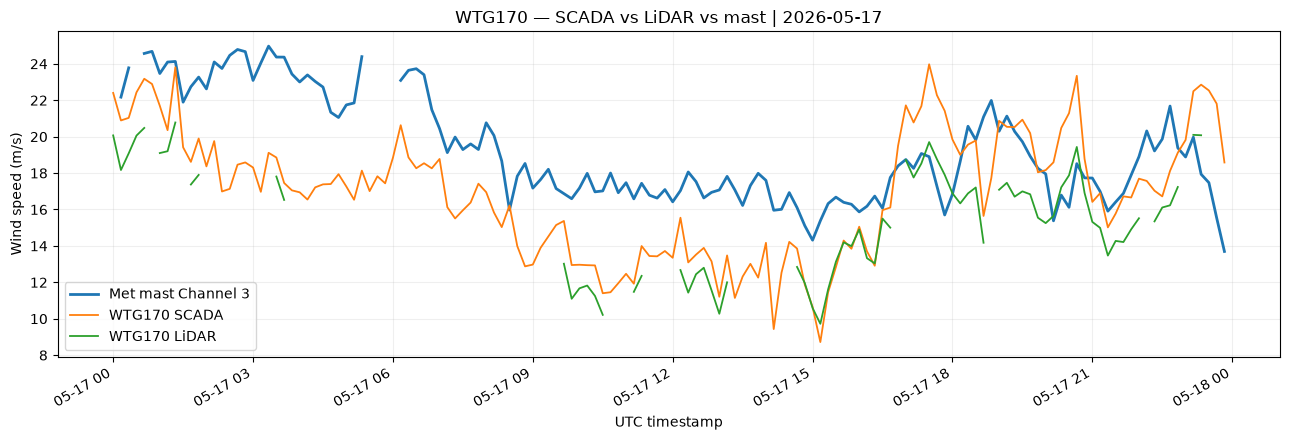


WTG170 THREE-SOURCE ANALYSIS COMPLETE

All results saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\15_WTG170_three_source\run_20261103T200319986348Z

These are measured differences relative to the working met-mast reference, not confirmed sensor errors.


In [1]:

# ============================================================
# 15 | WTG170 — SCADA vs LiDAR vs MET MAST
#
# No neighboring-turbine or power-data requirements.
# Uses the existing Jensen wake classifications.
#
# Outputs:
# - Measurement coverage
# - Same-timestamp three-source comparison
# - Monthly comparison
# - Scatterplots against mast
# - Detailed plots of unusual dates
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

TARGET = "WTG170"

SCADA_WAKE = (
    ROOT
    / "data/processed/12_farmwide_wake_exposure"
    / "scada_wake_comparison"
    / "ALTA10_SCADA_with_wake_categories.parquet"
)

LIDAR = (
    ROOT
    / "data/processed/06_research_synthesis"
    / "02_lidar_all_10min.csv"
)

BASE_11 = (
    ROOT
    / "data/processed/11_WTG159_mast_reference"
)

SAVE = (
    ROOT
    / "data/processed/15_WTG170_three_source"
    / (
        "run_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%S%fZ"
        )
    )
)

for path in [SCADA_WAKE, LIDAR]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}")


# ------------------------------------------------------------
# 1. Helpers
# ------------------------------------------------------------

def to_wtg(value):

    if pd.isna(value):
        return pd.NA

    match = re.fullmatch(
        r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?",
        str(value).strip().upper()
    )

    if match is None:
        raise ValueError(
            f"Unrecognized turbine ID: {value!r}"
        )

    return f"WTG{int(match.group(1))}"


def clean_times(table, source):

    if (
        "timestamp" not in table
        and "utc" not in table
    ):
        table = table.reset_index()

    field = next(
        (
            c for c in ["timestamp", "utc"]
            if c in table
        ),
        None
    )

    if field is None:
        raise KeyError(
            f"{source} has no timestamp or utc field"
        )

    table["timestamp"] = pd.to_datetime(
        table[field],
        utc=True,
        errors="coerce"
    )

    if table.timestamp.isna().any():
        raise ValueError(
            f"{source} contains invalid timestamps"
        )

    if (
        table.timestamp
        != table.timestamp.dt.floor("10min")
    ).any():
        raise ValueError(
            f"{source}: timestamps not on 10-minute grid"
        )

    if table.timestamp.duplicated().any():
        raise ValueError(
            f"{source} has duplicate timestamps"
        )

    return table


# ------------------------------------------------------------
# 2. Load WTG170 SCADA and met-mast measurements
# ------------------------------------------------------------

columns = [
    "timestamp",
    "turbine",
    "wind_speed",
    "mast_wind_speed_ms",
    "mast_wind_from_deg",
    "jensen_max_deficit_pct"
]

s = pd.read_parquet(
    SCADA_WAKE,
    columns=columns
)

s = s.loc[
    s.turbine.astype("string").eq(TARGET)
].copy()

if s.empty:
    raise ValueError(
        f"{TARGET} is not present in Dataset 1"
    )

s = clean_times(
    s,
    "WTG170 SCADA and met mast"
)

s = s.rename(
    columns={
        "wind_speed": "scada_ms",
        "mast_wind_speed_ms": "mast_ms",
        "mast_wind_from_deg": "mast_direction_deg",
        "jensen_max_deficit_pct": "target_wake_max_pct"
    }
)

s = s[
    [
        "timestamp",
        "scada_ms",
        "mast_ms",
        "mast_direction_deg",
        "target_wake_max_pct"
    ]
].copy()


# ------------------------------------------------------------
# 3. Load WTG170 LiDAR observations
# ------------------------------------------------------------

# Read the full 10-minute aggregate, retaining low readings.
# Require at least 540 valid seconds per interval.

l = pd.read_csv(
    LIDAR,
    low_memory=False
)

if not {
    "turbine",
    "valid_seconds"
}.issubset(l.columns):
    raise KeyError(
        "LiDAR source needs turbine and valid_seconds"
    )

wind_col = next(
    (
        c for c in ["mean_speed", "lidar_speed"]
        if c in l.columns
    ),
    None
)

if wind_col is None:
    raise KeyError(
        "LiDAR source needs mean_speed or lidar_speed"
    )

l["turbine"] = l.turbine.map(to_wtg)

l = l.loc[
    l.turbine.eq(TARGET)
].copy()

if l.empty:
    raise ValueError(
        "No WTG170 observations in LiDAR aggregate"
    )

l = clean_times(
    l,
    "WTG170 LiDAR"
)

l = l.rename(
    columns={
        wind_col: "lidar_raw_ms",
        "valid_seconds": "lidar_valid_seconds"
    }
)

l = l[
    [
        "timestamp",
        "lidar_raw_ms",
        "lidar_valid_seconds"
    ]
].copy()


# ------------------------------------------------------------
# 4. Optional mast wake screening from notebook 11
# ------------------------------------------------------------

# Notebook 11 already modeled wake exposure at the
# met-mast location. Its mast result can be reused here.
# WTG170's own wake classification comes from Dataset 1.

mast_wake_source = (
    "Unavailable — only WTG170 target wake can be screened"
)

runs11 = sorted(
    [
        p for p in BASE_11.glob("run_*")
        if (
            p / "11_all_aligned_observations.csv"
        ).is_file()
    ],
    reverse=True
)

m = None

if runs11:

    mast_file = (
        runs11[0]
        / "11_all_aligned_observations.csv"
    )

    header = pd.read_csv(
        mast_file,
        nrows=0
    ).columns.tolist()

    optional_columns = [
        c for c in [
            "primary_mast_wake_max_pct",
            "mast_hh_ms"
        ]
        if c in header
    ]

    if "primary_mast_wake_max_pct" in optional_columns:

        m = pd.read_csv(
            mast_file,
            usecols=["timestamp"] + optional_columns
        )

        m = clean_times(
            m,
            "Saved met-mast wake observations"
        )

        m = m.rename(
            columns={
                "primary_mast_wake_max_pct":
                    "mast_wake_max_pct"
            }
        )

        mast_wake_source = str(mast_file)


# ------------------------------------------------------------
# 5. Align all measurements at identical timestamps
# ------------------------------------------------------------

d = s.merge(
    l,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

if m is not None:

    d = d.merge(
        m,
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

d = (
    d.set_index("timestamp")
    .sort_index()
)

for col in d.columns:
    d[col] = pd.to_numeric(
        d[col],
        errors="coerce"
    )

# Plausibility and completeness checks.
# Low LiDAR speeds are deliberately retained.

d["lidar_complete"] = (
    d.lidar_valid_seconds >= 540
)

d["scada_valid"] = (
    d.scada_ms.between(0, 50)
)

d["lidar_valid"] = (
    d.lidar_complete
    & d.lidar_raw_ms.between(0, 50)
)

d["mast_valid"] = (
    d.mast_ms.between(3, 25)
)

d["all_three_valid"] = (
    d.scada_valid
    & d.lidar_valid
    & d.mast_valid
)

d["lidar_ms"] = (
    d.lidar_raw_ms.where(d.lidar_valid)
)

# Existing Jensen target wake classification:
# Low predicted wake = less than 2%.

d["target_low_wake"] = (
    d.target_wake_max_pct < 2
)

if "mast_wake_max_pct" in d.columns:

    d["joint_low_wake"] = (
        d.target_low_wake
        & d.mast_wake_max_pct.lt(2)
    )

else:

    d["joint_low_wake"] = False


# ------------------------------------------------------------
# 6. Calculate three measurement differences
# ------------------------------------------------------------

d["scada_minus_mast"] = (
    d.scada_ms - d.mast_ms
)

d["lidar_minus_mast"] = (
    d.lidar_ms - d.mast_ms
)

d["scada_minus_lidar"] = (
    d.scada_ms - d.lidar_ms
)


# ------------------------------------------------------------
# 7. Define comparable samples
# ------------------------------------------------------------

samples = {
    "All three valid":
        d.all_three_valid,

    "All three + WTG170 low predicted wake":
        d.all_three_valid
        & d.target_low_wake
}

if m is not None:

    samples[
        "All three + target AND mast low wake"
    ] = (
        d.all_three_valid
        & d.joint_low_wake
    )

    samples[
        "Joint low wake + mast 7–10 m/s"
    ] = (
        d.all_three_valid
        & d.joint_low_wake
        & d.mast_ms.between(7, 10)
    )

else:

    samples[
        "Target low wake + mast 7–10 m/s"
    ] = (
        d.all_three_valid
        & d.target_low_wake
        & d.mast_ms.between(7, 10)
    )


# ------------------------------------------------------------
# 8. Day-block bootstrap confidence intervals
# ------------------------------------------------------------

def day_bootstrap_ci(
    frame,
    variable,
    seed=170,
    draws=1500
):

    daily = frame.groupby(
        frame.index.floor("D")
    )[variable].agg(
        ["sum", "count"]
    )

    daily = daily.loc[
        daily["count"] > 0
    ]

    if (
        len(daily) < 10
        or daily["count"].sum() < 50
    ):
        return np.nan, np.nan

    rng = np.random.default_rng(seed)

    selected = rng.integers(
        0,
        len(daily),
        size=(draws, len(daily))
    )

    boot_means = (
        daily["sum"].to_numpy()[selected].sum(axis=1)
        /
        daily["count"].to_numpy()[selected].sum(axis=1)
    )

    return tuple(
        np.quantile(
            boot_means,
            [0.025, 0.975]
        )
    )


rows = []

for label, mask in samples.items():

    part = d.loc[mask].copy()

    result = {
        "sample": label,
        "records": len(part),
        "days": part.index.floor("D").nunique()
    }

    for name in [
        "scada_minus_mast",
        "lidar_minus_mast",
        "scada_minus_lidar"
    ]:

        low, high = day_bootstrap_ci(
            part,
            name
        )

        result[f"{name}_mean_ms"] = (
            part[name].mean()
        )

        result[f"{name}_median_ms"] = (
            part[name].median()
        )

        result[f"{name}_mean_absolute_ms"] = (
            part[name].abs().mean()
        )

        result[f"{name}_ci_low"] = low
        result[f"{name}_ci_high"] = high

    rows.append(result)

summary = pd.DataFrame(rows)


# ------------------------------------------------------------
# 9. Data coverage
# ------------------------------------------------------------

coverage = pd.DataFrame([
    {
        "stage": "WTG170 SCADA records",
        "records": len(d)
    },
    {
        "stage": "SCADA valid",
        "records": int(d.scada_valid.sum())
    },
    {
        "stage": "LiDAR complete and plausible",
        "records": int(d.lidar_valid.sum())
    },
    {
        "stage": "Mast 3–25 m/s",
        "records": int(d.mast_valid.sum())
    },
    *[
        {
            "stage": name,
            "records": int(mask.sum())
        }
        for name, mask in samples.items()
    ]
])


# ------------------------------------------------------------
# 10. Monthly comparison
# ------------------------------------------------------------

# Use target low-wake observations.
# The mast may still experience unmodeled or modeled wakes
# unless the joint-low-wake screen is separately applied.

q = d.loc[
    d.all_three_valid
    & d.target_low_wake
].copy()

q["month"] = (
    q.index.strftime("%Y-%m")
)

q["day"] = (
    q.index.floor("D")
)

monthly = (
    q.groupby("month")
    .agg(
        records=("scada_ms", "size"),

        days=("day", "nunique"),

        scada_minus_mast_mean_ms=(
            "scada_minus_mast", "mean"
        ),

        lidar_minus_mast_mean_ms=(
            "lidar_minus_mast", "mean"
        ),

        scada_minus_lidar_mean_ms=(
            "scada_minus_lidar", "mean"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# 11. Identify dates worth closer inspection
# ------------------------------------------------------------

# Rank by absolute SCADA–LiDAR disagreement.
# These are descriptive candidates, NOT sensor-fault flags.

q["abs_scada_lidar"] = (
    q.scada_minus_lidar.abs()
)

daily = (
    q.groupby("day")
    .agg(
        records=("abs_scada_lidar", "size"),

        mean_abs_scada_lidar_ms=(
            "abs_scada_lidar", "mean"
        ),

        mean_scada_minus_mast_ms=(
            "scada_minus_mast", "mean"
        ),

        mean_lidar_minus_mast_ms=(
            "lidar_minus_mast", "mean"
        )
    )
    .reset_index()
    .sort_values(
        "mean_abs_scada_lidar_ms",
        ascending=False
    )
)

# Require at least 12 observations on a day
# before selecting it for detailed plotting.

plot_dates = daily.loc[
    daily.records >= 12,
    "day"
].head(3)


# ------------------------------------------------------------
# 12. Save output tables
# ------------------------------------------------------------

SAVE.mkdir(
    parents=True,
    exist_ok=False
)

d.reset_index().to_parquet(
    SAVE / "15_WTG170_all_three_aligned.parquet",
    index=False
)

coverage.to_csv(
    SAVE / "15_sample_coverage.csv",
    index=False
)

summary.to_csv(
    SAVE / "15_three_source_comparison.csv",
    index=False
)

monthly.to_csv(
    SAVE / "15_monthly_low_target_wake.csv",
    index=False
)

daily.to_csv(
    SAVE / "15_days_ranked_by_scada_lidar_disagreement.csv",
    index=False
)


# ------------------------------------------------------------
# 13. Display numerical results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WTG170 — SCADA / LiDAR / MET MAST")
print("=" * 70)

print("\nLiDAR source:", LIDAR)
print("\nMast-wake source:", mast_wake_source)

print("\nDATA COVERAGE")
display(coverage)

print("\nTHREE-SOURCE MEASUREMENT DIFFERENCES")
print("Means, medians and 95% day-bootstrap intervals")
display(summary.round(3))

print("\nMONTHLY DIFFERENCES")
display(monthly.round(3))

print("\nTOP DATES BY SCADA–LiDAR DISAGREEMENT")
display(daily.head(10).round(3))


# ------------------------------------------------------------
# 14. Figure 1 — SCADA and LiDAR against the met mast
# ------------------------------------------------------------

all_valid = d.loc[
    d.all_three_valid
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, sensor, name in [
    (axes[0], "scada_ms", "SCADA"),
    (axes[1], "lidar_ms", "LiDAR")
]:

    ax.scatter(
        all_valid.mast_ms,
        all_valid[sensor],
        s=5,
        alpha=0.20
    )

    ax.plot(
        [0, 30],
        [0, 30],
        "--",
        color="black",
        linewidth=1,
        label="Equal reported speeds"
    )

    ax.set(
        xlabel="Met mast wind speed (m/s)",
        ylabel=f"WTG170 {name} wind speed (m/s)",
        title=f"{name} vs met mast"
    )

    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.tight_layout()

fig.savefig(
    SAVE / "15_scada_lidar_vs_mast.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 15. Figure 2 — Monthly measurement differences
# ------------------------------------------------------------

if not monthly.empty:

    fig, ax = plt.subplots(
        figsize=(11, 4)
    )

    for col, label in [
        ("scada_minus_mast_mean_ms", "SCADA − mast"),
        ("lidar_minus_mast_mean_ms", "LiDAR − mast"),
        ("scada_minus_lidar_mean_ms", "SCADA − LiDAR")
    ]:

        ax.plot(
            monthly.month,
            monthly[col],
            marker="o",
            label=label
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set(
        xlabel="Month (UTC)",
        ylabel="Average measurement difference (m/s)",
        title="WTG170 — Monthly wind-speed comparisons"
    )

    ax.legend()
    ax.grid(alpha=0.2)

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        SAVE / "15_monthly_differences.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 16. Figure 3 — Three highest-disagreement days
# ------------------------------------------------------------

for stamp in plot_dates:

    start = pd.Timestamp(stamp)

    times = pd.date_range(
        start,
        periods=144,
        freq="10min"
    )

    day = d.reindex(times)

    fig, ax = plt.subplots(
        figsize=(13, 4.5)
    )

    ax.plot(
        times,
        day.mast_ms.where(day.mast_valid),
        label="Met mast Channel 3",
        linewidth=2
    )

    ax.plot(
        times,
        day.scada_ms.where(day.scada_valid),
        label="WTG170 SCADA",
        linewidth=1.3
    )

    ax.plot(
        times,
        day.lidar_ms,
        label="WTG170 LiDAR",
        linewidth=1.3
    )

    ax.set(
        xlabel="UTC timestamp",
        ylabel="Wind speed (m/s)",
        title=(
            f"WTG170 — SCADA vs LiDAR vs mast | "
            f"{start.date()}"
        )
    )

    ax.grid(alpha=0.2)
    ax.legend()

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        SAVE / f"15_event_{start:%Y-%m-%d}.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 17. Complete
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WTG170 THREE-SOURCE ANALYSIS COMPLETE")
print("=" * 70)

print("\nAll results saved to:")
print(SAVE)

print(
    "\nThese are measured differences relative to the "
    "working met-mast reference, not confirmed sensor errors."
)
